# Validating CoLoRe simulation for GAL auto and GAL $\times$ CMB lensing

- The first and second CoLoRe simulation boxes were generated by Laura Casas, Dani L. Jarque run the rest from then on.
- The notebook uses the sources output from CoLoRe, i.e. quasars, to validate the simulation through the auto-spectrum and cross spectrum with CMB lensing.
    - The kappa map (`out_kappa_z000.fits`) can be found in `./data/x_test_box/cmb_lensing/`, along with $C_{\ell}^{\kappa \kappa}$, the corresponding errorbars, and a logarithmic rebinning run with `./scripts/generate_rebinned_cls.py`.
    - The QSO catalogs (`out_srcs_sx_xx.fits`) can be found in `./data/x_test_box/desi_qso)/`, along with $C_{\ell}^{qq}$, the corresponding errorbars, and a logarithmic rebinning run with `./scripts/generate_rebinned_cls.py`.
    - The kappa $\times$ QSO spectrum $C_{\ell}^{\kappa q}$ can be found in `./data/x_test_box/desi_qso/` with the corresponding errorbars, and a logarithmic rebinning run with `./scripts/generate_rebinned_cls.py`.
- The notebook also fits for two parameter in the modelling accounting for CoLoRe finite cell size and a rescaling of the theory bias.

In [37]:
import numpy as np
import matplotlib.pyplot as plt
import camb
import healpy as hp

from scipy.stats import chi2
from scipy.optimize import minimize
from scipy.interpolate import interp1d, PchipInterpolator
from scipy.integrate import simpson
from scipy.constants import c
import zeus, corner
import sys
sys.path.append('../')

from utils.rebinning import hybrid_bin_cls, merge_sources_catalogs
import json

# functions

## Theory

### setting up CAMB

In [38]:
def load_cosmology(filename):
    with open(filename) as f:
        return json.load(f)

In [39]:
def get_camb_results(
    cosmo_dict,
    z_pk,
    kmax=100.0,
    lmax=2500,
    nonlinear=False,
):
    """
    Read a cosmological parameter dictionary, extract cosmological parameters,
    and build CAMB results instance
    """

    # Convert to CAMB inputs

    H0 = 100.0 * cosmo_dict["h"]
    ombh2 = cosmo_dict["omega_B"] * cosmo_dict["h"]**2
    omch2 = (cosmo_dict["omega_M"] - cosmo_dict["omega_B"]) * cosmo_dict["h"]**2

    # Initial CAMB params

    pars = camb.CAMBparams()
    pars.set_cosmology(
        H0=H0,
        ombh2=ombh2,
        omch2=omch2,
    )
    pars.set_dark_energy(w=cosmo_dict["w"])
    pars.InitPower.set_params(
        ns=cosmo_dict["ns"],
        As=cosmo_dict["As"]
    )

    # Matter power settings

    pars.set_matter_power(
        redshifts=z_pk,
        kmax=kmax
    )

    # note that to get CAMB's internal calculation accurate at the 1% level at L~2000,
    # need lens_potential_accuracy=2. Increase to 4 for accurate match to the Limber calculation here
    if nonlinear:
        pars.NonLinear = camb.model.NonLinear_pk
        pars.set_for_lmax(lmax=lmax, lens_potential_accuracy=4, nonlinear=True)
    else:
        pars.set_for_lmax(lmax=lmax, lens_potential_accuracy=4, nonlinear=False)

    # Final results
    results = camb.get_results(pars)

    return results

### manual Limber integral

In [40]:
def W_g(z, kernel_context, kernel_args):
    '''
    Galaxy clustering kernel.
    '''

    # jacobian of transforming n(chi)=dN/dchi to n(z)=dN/dz, i.e. dchi/dz 
    c_kms = c * 1e-3
    Hz = kernel_context["Hz"]

    bz_interp = kernel_args["bz_interp"]
    nz_interp = kernel_args["nz_interp"]
    A_bias = kernel_args["A_bias"]

    bias = A_bias * bz_interp(z)
    ndensity = nz_interp(z)

    return bias * ndensity * (Hz / c_kms)

In [41]:
def W_kappa(z, kernel_context, kernel_args):
    '''
    CMB lensing convergence kernel.
    '''

    # geometry
    a = 1.0 / (1.0 + z)

    # comoving distance to lens and source
    chi = kernel_context["chi"]
    chi_source = kernel_context["chi_source"]

    # cosmological parameters
    H0, om = kernel_context["cosmo_params"]
    c_kms = c * 1e-3

    # kernel prefactor
    W_prefactor = 1.5 * (H0 / c_kms)**2 * om * (chi_source - chi) / chi_source
    W_geom = chi / a

    return W_prefactor * W_geom

In [42]:
def limber(
    z,
    ell,
    kmax,
    W1,
    W2,
    kernel_context,
    pk_interp,
    kp,
):
    '''
    General Limber integrand.
    '''

    # chi(z) and wavenumber of Limber approximation
    chi = kernel_context["chi"]
    k = (ell + 0.5) / chi

    # jacobian dchi/dz of the transformation integrating over z instead of chi
    c_kms = c * 1e-3
    Hz = kernel_context["Hz"]

    # avoid extrapolation of CAMB kmax and small scales
    mask = (k > 1e-4) & (k < kmax)
    out = np.zeros_like(k)

    # compute the Limber integrand only where valid
    if np.any(mask):

        # matter power spectrum
        pk = np.zeros_like(k)
        pk[mask] = pk_interp.P(
            z[mask],
            k[mask],
            grid=False
        )
        # smoothing
        smooth = np.exp(-(k / kp)**2)

        out[mask] = (
            (c_kms / Hz[mask])
            * ((W1[mask] * W2[mask]) / chi[mask]**2)
            * pk[mask]
            * smooth[mask]
        )

    return out

In [43]:
def get_limber_cls(
    params_path,
    z_pk,
    kernel1,
    kernel2,
    kernel1_args,
    kernel2_args,
    nside1,
    nside2,
    kmax=100,
    lmin=2,
    lmax=2500,
    kp=None, # default fitted smoothing scale in (1/Mpc)
):
    '''
    Compute the angular qq/kq power spectra using the Limber approximation.
    '''

    # get cosmological parameters
    cosmo_dict = load_cosmology(params_path)
    z_max = cosmo_dict["z_max"]

    # get CAMB results
    results_lin = get_camb_results(
        cosmo_dict=cosmo_dict,
        z_pk=z_pk,
        kmax=kmax,
        lmax=lmax,
        nonlinear=False
    )

    # get matter power spectrum interpolator
    pk_interp_lin = results_lin.get_matter_power_interpolator(
        nonlinear=False,
        hubble_units=False,
        k_hunit=False,
        var1='delta_tot',
        var2='delta_tot'
    )

    # compute source comoving distance for CMB lensing
    z_star = results_lin.get_derived_params()['zstar']
    chi_star = results_lin.comoving_radial_distance(z_star)

    # cosmological parameters needed by kernels
    H0 = cosmo_dict["h"] * 100
    om = cosmo_dict["omega_M"]

    # shared kernel context
    chi_source = chi_star
    kernel_context = {
        "results": results_lin,
        "chi_source": chi_source,
        "cosmo_params": (H0, om),
    }

    # multipoles and cls
    ells = np.arange(lmin, lmax + 1)
    cls = np.zeros_like(ells, dtype=np.float64)

    # precompute the z, chi(z) and H(z) grids for Limber integrand
    z_grid = np.linspace(1e-4, z_max, 1000)
    chi_grid = results_lin.comoving_radial_distance(z_grid)
    Hz_grid = results_lin.hubble_parameter(z_grid)

    # add to kernel context for use in kernels and Limber integrand
    kernel_context["chi"] = chi_grid
    kernel_context["Hz"] = Hz_grid

    # precompute kernels on the z grid
    W1_grid = kernel1(z_grid, kernel_context, kernel1_args)
    W2_grid = kernel2(z_grid, kernel_context, kernel2_args)

    # integrate Limber approximation
    for i, ell in enumerate(ells):

        integrand = limber(
            z_grid,
            ell,
            kmax,
            W1_grid,
            W2_grid,
            kernel_context,
            pk_interp_lin,
            kp,
        )

        cls[i] = simpson(integrand, x=z_grid)

    # smooth with healpix pixel window function of the two fields
    lmax_map1 = nside1 * 3 - 1
    lmax_map2 = nside2 * 3 - 1
    lmax_min = np.min([lmax_map1, lmax_map2, lmax])
    pixwin1 = hp.pixwin(nside1)
    pixwin2 = hp.pixwin(nside2)
    pixwin1 = pixwin1[lmin : (lmax_min + 1)]
    pixwin2 = pixwin2[lmin : (lmax_min + 1)]
    ells = ells[:(lmax_min + 1 - lmin)]
    cls = cls[:(lmax_min + 1 - lmin)]
    cls_smoothed = cls * pixwin1 * pixwin2

    return {
        "ells": ells,
        "cls": cls_smoothed,
    }

## Data

### get colore output

In [44]:
def get_colore_cls(box_filename):
    '''
    Load the Colore kappa power spectrum from a text file
    '''

    # load the data from the .npz file
    data = np.load(box_filename)
    ells, cl, err = data['ells'], data['cls'], data['err']

    return ells, cl, err

## plotting functions

In [45]:
def plot_cls_gg_comparison(ells_sim, cl_gg_sim, err_gg_sim, ells, cl_gg_lin, cl_gg_lin_rebin, 
                           lmin_fit, lmax_fit, kp_gg, err_kp, Abias_gg,  err_Abias, 
                           box_label, plot_title='', test_name=''):

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(6, 5), height_ratios=[2.5, 1], dpi=120, sharex=True, gridspec_kw={'hspace':0.05})

    for ax in (ax1, ax2):
        ax.tick_params(
            which='both',
            direction='in',
            top=True,
            right=True
        )

    # compute the reduced chi-squared between the rebinned linear limber and the rebinned CoLoRecls
    chi2 = np.sum((cl_gg_sim - cl_gg_lin_rebin)**2 / err_gg_sim**2)
    chi2_nu = chi2 / (len(ells_sim))

    # plot the rebinned CoLoRe Cls with error bars
    ax1.errorbar(ells_sim, cl_gg_sim, yerr=err_gg_sim, fmt='k.', ms=5.0,
                 elinewidth=0.8, capsize=2.0, ecolor='k',
                 label=rf'CoLoRe_{box_label}')
    ax1.scatter(0, 0, s=0, 
            label=rf'$\chi^2_\nu = {chi2_nu:.2f}$')
    ax1.scatter(0, 0, s=0, label=rf'$(k_p= {kp_gg:.3f} \pm {err_kp:.3f} \ 1/\rm{{Mpc}} \ | \ A_{{bias}}= {Abias_gg:.3f} \pm {err_Abias:.3f})$')

    # manual limber integration full redshift
    ax1.plot(ells, cl_gg_lin, c='C0', ls='-', label=rf'Limber_linear')

    # shade most sensitive region to the analysis
    ax1.axvspan(lmin_fit, lmax_fit, color='gray', alpha=0.1, label='Fitting region')

    ax1.set_xscale('log')
    ax1.set_yscale('log')
    ax1.set_xlim(1.5, 3000)
    ax1.set_ylabel(r'$C_{L}^{gg}$')
    ax1.legend(loc='lower left')

    ax1.grid(True, which='major', alpha=0.25)
    #ax1.grid(True, which='minor', alpha=0.10)

    # plot the relative error between the rebinned linear limber and the rebinned CoLoRe cls
    chi2_bin = (cl_gg_sim - cl_gg_lin_rebin) / err_gg_sim

    # plot the relative error for low multipoles in the main panel
    ax2.errorbar(ells_sim, chi2_bin, fmt='k.', ms=5.0, mec='k')
    ax2.axhspan(-1, 1, color='C0', alpha=0.12)
    ax2.axvspan(lmin_fit, lmax_fit, color='gray', alpha=0.15, label='Fitting region')
    ax2.axhline(0, color='0.35', ls='--', lw=1.0, zorder=0)
    ax2.set_xscale('log')
    ax2.set_xlabel(r'Multipole $L$')
    ax2.set_ylabel(r'$\Delta C_L^{gg}/\sigma$')
    ax2.set_ylim(-5, 5)

    fig.suptitle(plot_title, y=1.01)
    fig.savefig(f'plots/cls_gg_{box_label}_{test_name}.png', bbox_inches='tight')
    fig.savefig(f'plots/cls_gg_{box_label}_{test_name}.pdf', bbox_inches='tight')
    plt.show()

In [46]:
def plot_cls_kg_comparison(ells_sim, cl_kg_sim, err_kg_sim, ells, cl_kg_lin, cl_kg_lin_rebin, 
                           lmin_fit, lmax_fit, kp_kg, err_kp, Abias_kg, err_Abias, 
                           box_label, plot_title='', test_name=''):

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(6, 5), height_ratios=[2.5, 1], dpi=120, sharex=True, gridspec_kw={'hspace':0.05})

    for ax in (ax1, ax2):
        ax.tick_params(
            which='both',
            direction='in',
            top=True,
            right=True
        )

    # compute the reduced chi-squared between the rebinned linear limber and the rebinned CoLoRe cls
    chi2 = np.sum((cl_kg_sim - cl_kg_lin_rebin)**2 / err_kg_sim**2)
    chi2_nu = chi2 / (len(ells_sim))

    # plot the rebinned CoLoRe Cls with error bars
    ax1.errorbar(ells_sim, cl_kg_sim, yerr=err_kg_sim, fmt='k.', ms=5.0,
                 elinewidth=0.8, capsize=2.0, ecolor='k',
                 label=rf'CoLoRe_{box_label}')
    ax1.scatter(0, 0, s=0, 
            label=rf'$\chi^2_\nu = {chi2_nu:.2f}$')
    ax1.scatter(0, 0, s=0, label=rf'$(k_p= {kp_kg:.3f} \pm {err_kp:.3f} \ 1/\rm{{Mpc}} \ | \ A_{{bias}}= {Abias_kg:.3f} \pm {err_Abias:.3f})$')

    # manual limber integration full redshift
    ax1.plot(ells, cl_kg_lin, c='C0', ls='-', label=rf'Limber_linear')

    # shade most sensitive region to the analysis
    ax1.axvspan(lmin_fit, lmax_fit, color='gray', alpha=0.1, label='Fitting region')

    ax1.set_xscale('log')
    ax1.set_yscale('log')
    ax1.set_xlim(1.5, 3000)
    ax1.set_ylabel(r'$C_{L}^{kg}$')
    ax1.legend(loc='lower left')
    ax1.grid(True, which='major', alpha=0.25)
    
    # plot the relative error between the rebinned linear limber and the rebinned CoLoRe cls
    chi2_bin = (cl_kg_sim - cl_kg_lin_rebin) / err_kg_sim

    # plot the relative error for low multipoles in the main panel
    ax2.errorbar(ells_sim, chi2_bin, fmt='k.', ms=5.0, mec='k')
    ax2.axhspan(-1, 1, color='C0', alpha=0.12)
    ax2.axvspan(lmin_fit, lmax_fit, color='gray', alpha=0.15, label='Fitting region')
    ax2.axhline(0, color='0.35', ls='--', lw=1.0, zorder=0) 
    ax2.set_xscale('log')
    ax2.set_xlabel(r'Multipole $L$')
    ax2.set_ylabel(r'$\Delta C_L^{kg}/\sigma$')
    ax2.set_ylim(-5, 5)

    fig.suptitle(plot_title, y=1.001)
    fig.savefig(f'plots/cls_kg_{box_label}_{test_name}.png', bbox_inches='tight')
    fig.savefig(f'plots/cls_kg_{box_label}_{test_name}.pdf', bbox_inches='tight')
    plt.show()

In [47]:
def plot_cls_kk_comparison(ells_sim, cl_kk_sim, err_kk_sim, ells, cl_kk_lin, cl_kk_lin_rebin, 
                           lmin_fit, lmax_fit, kp_kk, err_kp, 
                           box_label, plot_title=''):

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(6, 5), height_ratios=[2.5, 1], dpi=120, sharex=True, gridspec_kw={'hspace':0.05})

    for ax in (ax1, ax2):
        ax.tick_params(
            which='both',
            direction='in',
            top=True,
            right=True
        )

    # compute the reduced chi-squared between the rebinned linear limber and the rebinned CoLoRe cls
    chi2 = np.sum((cl_kk_sim - cl_kk_lin_rebin)**2 / err_kk_sim**2)
    chi2_nu = chi2 / (len(ells_sim))

    # plot the rebinned CoLoRe Cls with error bars
    ax1.errorbar(ells_sim, cl_kk_sim, yerr=err_kk_sim, fmt='k.', ms=5.0,
                 elinewidth=0.8, capsize=2.0, ecolor='k',
                 label=rf'CoLoRe_{box_label}')
    ax1.scatter(0, 0 , s=0, label=rf'$\chi^2_\nu = {chi2_nu:.2f} \ \ (k_p= {kp_kk:.3f} \pm {err_kp:.3f} \ 1/\rm{{Mpc}})$')

    # manual limber integration full redshift
    ax1.plot(ells, cl_kk_lin, c='C0', ls='-', label=rf'Limber_linear')

    # shade most sensitive region to the analysis
    ax1.axvspan(lmin_fit, lmax_fit, color='gray', alpha=0.1, label='Fitting region')
    
    ax1.set_xscale('log')
    ax1.set_yscale('log')
    ax1.set_xlim(1.5, 3000)
    ax1.set_ylabel(r'$C_{L}^{kk}$')
    ax1.legend(loc='lower left')
    ax1.grid(True, which='major', alpha=0.25)
    
    # plot the relative error between the rebinned linear limber and the rebinned CoLoRe cls
    chi2_bin = (cl_kk_sim - cl_kk_lin_rebin) / err_kk_sim

    # plot the relative error for low multipoles in the main panel
    ax2.errorbar(ells_sim, chi2_bin, fmt='k.', ms=5.0, mec='k')
    ax2.axhspan(-1, 1, color='C0', alpha=0.12)
    ax2.axvspan(lmin_fit, lmax_fit, color='gray', alpha=0.15, label='Fitting region')
    ax2.axhline(0, color='0.35', ls='--', lw=1.0, zorder=0) 
    ax2.set_xscale('log')
    ax2.set_xlabel(r'Multipole $L$')
    ax2.set_ylabel(r'$\Delta C_L^{kk}/\sigma$')
    ax2.set_ylim(-5, 5)

    fig.suptitle(plot_title, y=1.001)
    fig.savefig(f'plots/cls_kk_{box_label}.png', bbox_inches='tight')
    fig.savefig(f'plots/cls_kk_{box_label}.pdf', bbox_inches='tight')
    plt.show()

In [48]:
def plot_cumulative_chi2(ells_colore, cl_xx_colore, err_xx, cl_xx_lin_rebin, box_label, plot_title='', test_name='', xx=''):

    # compute the cumulative chi-square and p-values for each multipole bin
    chi2_per_bin = ((cl_xx_colore - cl_xx_lin_rebin) / err_xx)**2
    cumulative_chi2 = np.nancumsum(chi2_per_bin)
    cumulative_dof = np.arange(1, len(cumulative_chi2) + 1)
    p_values = 1 - chi2.cdf(cumulative_chi2, df=cumulative_dof)

    # Plotting the cumulative chi-square
    fig, ax1 = plt.subplots(figsize=(6, 4), dpi=120)
    ax2 = ax1.twinx()  # Create a second y-axis for p-values

    # Plot your cumulative chi-square
    ax1.plot(ells_colore, cumulative_chi2, marker='.', linestyle='-', color='C0', label=rf'Cumulative $\chi^2$ ({box_label})')
    ax2.plot(ells_colore, p_values, marker='.', linestyle='-', color='C1', label=r'Cumulative $p$-value', alpha=0.3)

    # Plot the expected theoretical baseline (Expected chi^2 = dof)
    ax1.plot(ells_colore, cumulative_dof, linestyle='--', color='black', label=r'Expected $\chi^2$ (Perfect Fit)')

    # Formatting the plot
    ax1.set_xscale('log')
    ax1.set_yscale('linear') # A log scale on the y-axis is highly recommended since the max value is ~8000
    ax1.set_xlabel('Multipole $L$')
    ax1.set_ylabel(r'Cumulative $\chi^2$')
    ax2.set_ylabel(r'Cumulative $p$-value')
    ax1.set_title(plot_title)
    ax1.legend(loc='upper left')
    ax2.legend(loc='upper right')

    test_suffix = f"_{test_name}" if test_name else ""
    fig.savefig(f'plots/cls_{xx}_{box_label}{test_suffix}_cumulative_chi2.png', bbox_inches='tight')  
    fig.savefig(f'plots/cls_{xx}_{box_label}{test_suffix}_cumulative_chi2.pdf', bbox_inches='tight')  

    plt.show()

## fitting functions

In [49]:
def get_limber_cls_fit(
    params,
    z_grid,
    pk_interp_lin,
    kernel1_grid,
    kernel2_grid,
    kernel_context,
    pixwin1,
    pixwin2,
    lmin_fit,
    lmax_fit,
    kmax=100,
    cmb=False,
):
    '''
    Compute the angular qq/kq power spectra using the Limber approximation.
    '''

    if cmb:
        kp = params
        amplitude = 1
    else:
        # fitting parameters
        kp, A_bias = params
        # squared bias in case of gg fitting
        if np.array_equal(kernel1_grid, kernel2_grid):
            amplitude = A_bias**2
        else:
            amplitude = A_bias

    # multipoles and cls
    ells = np.arange(lmin_fit, lmax_fit + 1)
    cls = np.zeros_like(ells, dtype=np.float64)

    # geometry
    chi = kernel_context["chi"][:, None]        # (Nz,1)
    Hz = kernel_context["Hz"][:, None]          # (Nz,1)
    c_kms = c * 1e-3

    # Limber k-grid (Nz, Nell)
    k = (ells[None, :] + 0.5) / chi

    # valid CAMB region
    mask = (k > 1e-4) & (k < kmax)

    # evaluate P(k,z) for all z and ell
    pk = np.zeros_like(k)
    pk[mask] = pk_interp_lin.P(
        np.broadcast_to(z_grid[:, None], k.shape)[mask],
        k[mask],
        grid=False,
    )

    # parameter-dependent smoothing
    smooth = np.exp(-(k / kp) ** 2)

    # full integrand
    base = (c_kms / Hz) * (kernel1_grid[:, None] * kernel2_grid[:, None]) / chi**2
    integrand = base * pk * smooth

    # integrate all multipoles simultaneously
    cls = amplitude * simpson(
        integrand,
        x=z_grid,
        axis=0,
    )

    # match the healpix pixel window function with length of cls
    lmax_map1 = len(pixwin1) - 1
    lmax_map2 = len(pixwin2) - 1
    lmax_min = np.min([lmax_map1, lmax_map2, lmax_fit])
    pixwin1 = pixwin1[lmin_fit : (lmax_min + 1)]
    pixwin2 = pixwin2[lmin_fit : (lmax_min + 1)]
    ells = ells[:(lmax_min + 1 - lmin_fit)]
    cls = cls[:(lmax_min + 1 - lmin_fit)]
    cls_smoothed = cls * pixwin1 * pixwin2

    return {
        "ells": ells,
        "cls": cls_smoothed,
    }

In [50]:
def get_chi2(
    params,
    z_grid,
    lmin_fit,
    lmax_fit,
    pk_interp_lin,
    kernel1_grid,
    kernel2_grid,
    kernel_context,
    pixwin1,
    pixwin2,
    cls_data,
    err_data,
    cmb=False,
    kmax=100.0,
):
    '''
    Reduced chi-squared for gg or gk fitting.
    '''

    # compute theory
    results = get_limber_cls_fit(
        params,
        z_grid,
        pk_interp_lin,
        kernel1_grid,
        kernel2_grid,
        kernel_context,
        pixwin1,
        pixwin2,
        lmin_fit,
        lmax_fit,
        kmax=kmax,
        cmb=cmb
    )

    # rebin theory
    _, cls_theory, _ = hybrid_bin_cls(
        results["ells"],
        results["cls"],
        nbins=len(cls_data),
        ell_min=lmin_fit,
        ell_max=lmax_fit,
    )

    # remove invalid values
    mask = (
        np.isfinite(cls_data)
        & np.isfinite(cls_theory)
        & np.isfinite(err_data)
        & (err_data > 0)
    )

    cls_data = cls_data[mask]
    cls_theory = cls_theory[mask]
    err_data = err_data[mask]

    # get chi2 statistic
    chi2 = np.sum(
        ((cls_data - cls_theory) / err_data)**2
    )

    if cmb:
        return chi2 / (len(cls_data) - 1)  # fitting 1 parameter
    else:
        return chi2 / (len(cls_data) - 2)  # fitting 2 parameters

# Theory GAL auto and GAL x CMB spectrums

## boltzmann parameters

In [53]:
# set the redshift range for the boltzmann solver
zmin, zmax = 0, 1100
nz = 200
z_pk = zmin + np.exp(np.log(zmax - zmin + 1)*np.linspace(0, 1, nz)) - 1
z_pk = z_pk[::-1] # reverse to have higher redshift first for better interpolation at high z
lmin, lmax = 2, 2500

## cross-check input and output n(z)

In [54]:
# choose the box for which to compare the theory and the CoLoRe Cls
box = 'fourth_test_box'  # options: 'third_test_box', 'fourth_test_box'
galaxy_catalog = 'lsst_gal'  # options: 'desi_bgs, 'desi_lrg', 'desi_qso', 'lsst_gal'
galaxy_catalog_bin = 'lsst_gal_bin1'  # options: 'desi_bgs, 'desi_lrg', 'desi_qso', 'lsst_gal'

# get the limber cls for the last box
nside_g = 512  # this nside has to match the one used to generate the colore Cls in the script
nside_k = 512  # this nside has to match the one used to generate the colore Cls in the script
params_path = f'../data/{box}/cosmo_params.json'

In [55]:
# load the galaxy catalogs, galaxy bias and redshift distribution, 
z_bz, bz = np.loadtxt(f'../data/colore_files/bz/bz_{galaxy_catalog}.txt', unpack=True)
z_nz_input, nz_input = np.loadtxt(f'../data/colore_files/nz/nz_{galaxy_catalog}.txt', unpack=True)
zbin_width_input = np.diff(z_nz_input)[0]

# load the n(z) histogram output from colore
z_edges, nz_output = np.load(f'../data/{box}/cls/nz_hist_{galaxy_catalog}.npz')['z_edges'], np.load(f'../data/{box}/cls/nz_hist_{galaxy_catalog}.npz')['nz']
zbin_width_output = np.diff(z_edges)[0]

# create n(z) interpolator for the input galaxy bias and redshift distribution
fsky = (4 * np.pi) * (180 / np.pi)**2  # multiply by the total sky area in deg**2 and redshift bin width
nz_input = nz_input * fsky * zbin_width_output
norm = simpson(nz_input, z_nz_input)
nz_interp_input = PchipInterpolator(z_nz_input, nz_input, extrapolate=False)
bz_interp = PchipInterpolator(z_bz, bz, extrapolate=False)

In [56]:
# full redshift range for interpolation plot
zmin = 0.0
zmax = 3.8
z = np.linspace(zmin, zmax, 1000)

# create n(z) interpolator for the output redshift distributions
z_nz_output = 0.5*(z_edges[:-1] + z_edges[1:])  # get the bins middle points
z_nz_output = np.concatenate(([zmin], z_nz_output, [zmax]))  # add the first and last bin edges to the middle points redshift
z_nz_output_min = nz_input[0]
z_nz_output_max = nz_input[np.abs(z_nz_input - 3.8).argmin()]

nz_output = np.concatenate(([z_nz_output_min], nz_output, [z_nz_output_max]))  # add the first and last bin edges to the middle points n(z)
nz_interp_output = PchipInterpolator(z_nz_output, nz_output, extrapolate=True)

In [57]:
# define the redshift tomographic bin of the analysis
zmin_bin = 2.0
zmax_bin = 3.8
zbin = np.linspace(zmin_bin, zmax_bin, 1000)
nz_output_bin = nz_output.copy()
nz_output_bin[(z_nz_output <= zmin_bin) | (z_nz_output >= zmax_bin)] = 0  # ensure the interpolator is zero outside the tomographic bin

# create n(z) interpolator for the tomographic bin output redshift distributions
norm = simpson(nz_interp_output(zbin), zbin)
nz_interp_output_bin = PchipInterpolator(z_nz_output, nz_output_bin/norm, extrapolate=True)

/tmp/ipykernel_42268/544734809.py:16: RuntimeWarning: divide by zero encountered in divide
  ratio = (nz_interp_output_bin(z)*norm - (nz_interp_input(z))) / nz_interp_input(z)
/tmp/ipykernel_42268/544734809.py:16: RuntimeWarning: invalid value encountered in divide
  ratio = (nz_interp_output_bin(z)*norm - (nz_interp_input(z))) / nz_interp_input(z)


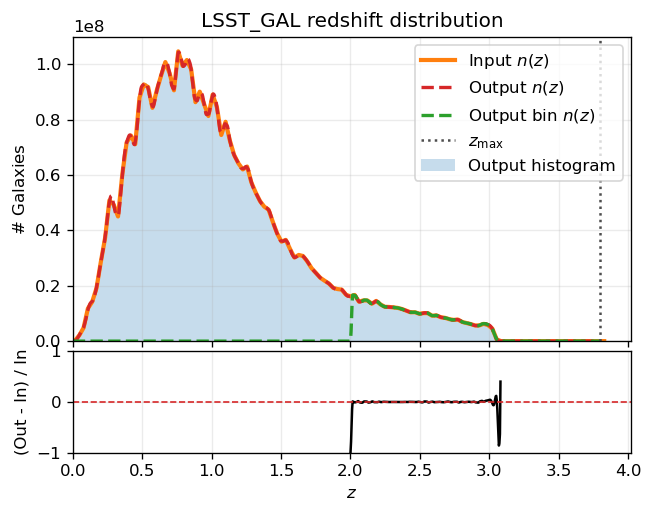

In [58]:
nbins = 400
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(6, 4.5), dpi=120, sharex=True, gridspec_kw={'height_ratios':[3,1], 'hspace':0.05})

# Top panel
ax1.bar(z_nz_output, nz_output, width=zbin_width_output, align='center', color='C0', alpha=0.25, label='Output histogram')  # align=edge is needed to match the histogram bins edges with the bars edges
ax1.plot(z_nz_input, nz_interp_input(z_nz_input), 'C1', lw=2.5, label=r'Input $n(z)$')
ax1.plot(z, nz_interp_output(z), 'C3--', lw=2, label=r'Output $n(z)$')
ax1.plot(z, nz_interp_output_bin(z)*norm, 'C2--', lw=2, label=r'Output bin $n(z)$')
ax1.axvline(3.8, color='0.3', ls=':', lw=1.5, label=r'$z_{\rm max}$')
ax1.set_ylabel(r'$\#$ Galaxies')
ax1.set_title(f'{galaxy_catalog.upper()} redshift distribution')
ax1.legend(frameon=True)
ax1.grid(alpha=0.25)

# Bottom panel
ratio = (nz_interp_output_bin(z)*norm - (nz_interp_input(z))) / nz_interp_input(z)
ratio[(nz_interp_input(z) == 0)] = np.nan # set to nan if nz_output is zero
ratio[(nz_interp_output_bin(z) == 0)] = np.nan # set to nan if nz_output is zero
ax2.plot(z, ratio, 'k', lw=1.5)
ax2.axhline(0, color='C3', ls='--', lw=1)
ax2.set_xlim(left=0)
ax2.set_ylim(-1, 1)
ax2.set_xlabel(r'$z$')
ax2.set_ylabel('(Out - In) / In')
ax2.grid(alpha=0.25)

plt.show()

## Compute the theory Cls

In [59]:
# fitted parameters
kp_gg = best_kp_gg # default fitted smoothing scale in (1/Mpc)
kp_kg = best_kp_kg # default fitted smoothing scale in (1/Mpc)
kp_kk = best_kp_kk # default fitted smoothing scale in (1/Mpc)
Abias_gg = best_Abias_gg # default fitted bias amplitude for the qq spectrum
Abias_kg = best_Abias_kg # default fitted bias amplitude for the kq spectrum

results_gg = get_limber_cls(
    params_path=params_path,
    z_pk=z_pk,
    kernel1=W_g,
    kernel2=W_g,
    kernel1_args={
        "bz_interp": bz_interp,
        "nz_interp": nz_interp_output_bin,
        "A_bias": Abias_gg,
    },
    kernel2_args={
        "bz_interp": bz_interp,
        "nz_interp": nz_interp_output_bin,
        "A_bias": Abias_gg,
    },
    nside1=nside_g,
    nside2=nside_g,
    kp=kp_gg
)

results_kg = get_limber_cls(
    params_path=params_path,
    z_pk=z_pk,
    kernel1=W_kappa,
    kernel2=W_g,
    kernel1_args={},
    kernel2_args={
        "bz_interp": bz_interp,
        "nz_interp": nz_interp_output_bin,
        "A_bias": Abias_kg,
    },
    nside1=nside_k,
    nside2=nside_g,
    kp=kp_kg
)

results_kk = get_limber_cls(
    params_path=params_path,
    z_pk=z_pk,
    kernel1=W_kappa,
    kernel2=W_kappa,
    kernel1_args={},
    kernel2_args={},
    nside1=nside_k,
    nside2=nside_k,
    kp=kp_kk
)

# extract the relevant results for the last box
keys = ['ells', 'cls']
ells_gg, cl_gg_lin = [results_gg[k] for k in keys]
ells_kg, cl_kg_lin = [results_kg[k] for k in keys]
ells_kk, cl_kk_lin = [results_kk[k] for k in keys]

# Simulation GAL auto and GAL x CMB spectrums

In [60]:
# determine the lmin and lmax from the sim data to ensure consistent binning for residuals
lmin_sim = lmin
lmax_gg_sim = nside_g * 3 - 1
lmax_kg_sim = nside_k * 3 - 1
lmax_kk_sim = nside_k * 3 - 1
nbins = 30

# make sure the tomographic binning of the theory matches the one used to generate the sim Cls
ells_gg_sim, cl_gg_sim, err_gg_sim = get_colore_cls(f'../data/{box}/cls/cl_gg_{galaxy_catalog_fit}_log.npz')
ells_kg_sim, cl_kg_sim, err_kg_sim = get_colore_cls(f'../data/{box}/cls/cl_kg_{galaxy_catalog_fit}_log.npz')
ells_kk_sim, cl_kk_sim, err_kk_sim = get_colore_cls(f'../data/{box}/cls/cl_kk_log.npz')

# rebin the CAMB linear and non-linear cls to match the number of bins in the Colore data for the relative error subplot
cl_gg_lin_rebin = hybrid_bin_cls(ells_gg, cl_gg_lin, nbins=nbins, ell_min=lmin_sim, ell_max=lmax_gg_sim)[1]
cl_kg_lin_rebin = hybrid_bin_cls(ells_kg, cl_kg_lin, nbins=nbins, ell_min=lmin_sim, ell_max=lmax_kg_sim)[1]
cl_kk_lin_rebin = hybrid_bin_cls(ells_kk, cl_kk_lin, nbins=nbins, ell_min=lmin_sim, ell_max=lmax_kk_sim)[1]

In [61]:
# filter out NaN values which may arise from empty bins in the rebinning process
mask_gg = np.isfinite(ells_gg_sim)
mask_kg = np.isfinite(ells_kg_sim)
mask_kk = np.isfinite(ells_kk_sim)
ells_gg_sim, cl_gg_sim, cl_gg_lin_rebin, err_gg_sim,  = [arr[mask_gg] for arr in [ells_gg_sim, cl_gg_sim, cl_gg_lin_rebin, err_gg_sim]]
ells_kg_sim, cl_kg_sim, cl_kg_lin_rebin, err_kg_sim = [arr[mask_kg] for arr in [ells_kg_sim, cl_kg_sim, cl_kg_lin_rebin, err_kg_sim]]
ells_kk_sim, cl_kk_sim, cl_kk_lin_rebin, err_kk_sim = [arr[mask_kk] for arr in [ells_kk_sim, cl_kk_sim, cl_kk_lin_rebin, err_kk_sim]]

# Plots

## latest CoLoRe box analysis and $\chi^2$ test

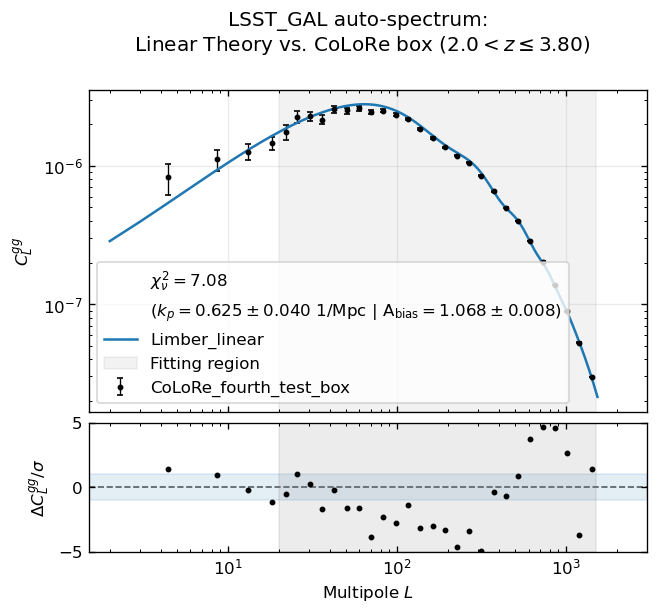

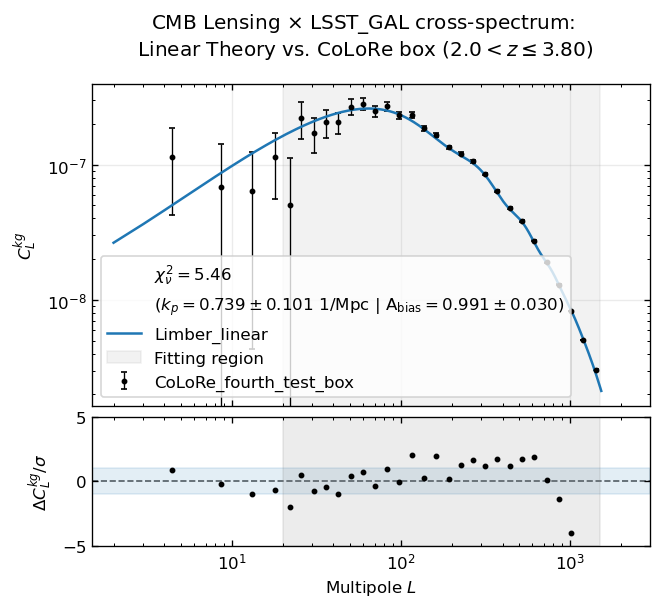

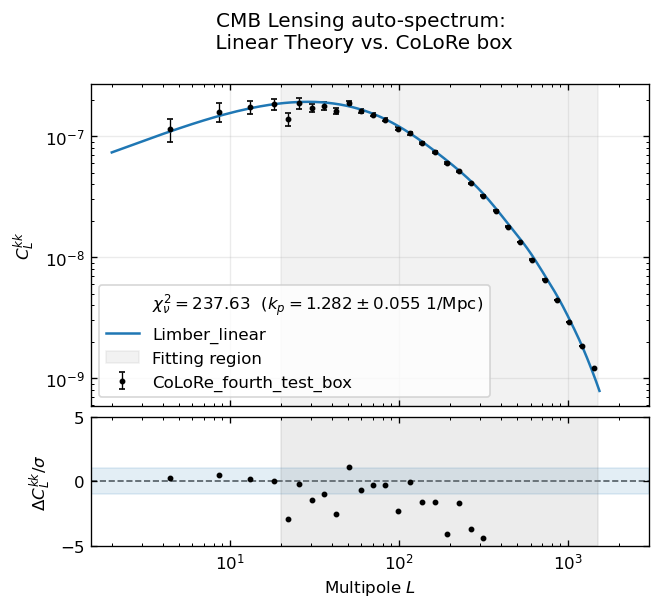

In [62]:
plot_cls_gg_comparison(ells_gg_sim, cl_gg_sim, err_gg_sim, ells_gg, cl_gg_lin, cl_gg_lin_rebin, 
                       lmin_fit_gg, lmax_fit_gg, kp_gg, errors_gg[0], Abias_gg, errors_gg[1],
                       box_label=box, 
                       plot_title=f'{galaxy_catalog.upper()} auto-spectrum:\n Linear Theory vs. CoLoRe box (${zmin_bin} < z \\leq {zmax_bin:.2f}$)',
                       test_name=f'{galaxy_catalog_bin}')
plot_cls_kg_comparison(ells_kg_sim, cl_kg_sim, err_kg_sim, ells_kg, cl_kg_lin, cl_kg_lin_rebin, 
                       lmin_fit_kg, lmax_fit_kg, kp_kg, errors_kg[0], Abias_kg, errors_kg[1],
                       box_label=box,
                       plot_title=f'CMB Lensing $\\times$ {galaxy_catalog.upper()} cross-spectrum:\n Linear Theory vs. CoLoRe box (${zmin_bin} < z \\leq {zmax_bin:.2f}$)',
                       test_name=f'{galaxy_catalog_bin}')
plot_cls_kk_comparison(ells_kk_sim, cl_kk_sim, err_kk_sim, ells_kk, cl_kk_lin, cl_kk_lin_rebin, 
                       lmin_fit_kk, lmax_fit_kk, kp_kk, errors_kk[0],
                       box_label=box,
                       plot_title=f'CMB Lensing auto-spectrum:\n Linear Theory vs. CoLoRe box')

In [ ]:
plot_cumulative_chi2(ells_gg_sim, cl_gg_sim, err_gg_sim, cl_gg_lin_rebin, 
                       box_label=box,
                       plot_title=f'{galaxy_catalog.upper()} auto-spectrum:\n Cumulative $\\chi^2$ vs. Multipole $L$',
                       test_name=f'{galaxy_catalog}',
                       xx='gg')
plot_cumulative_chi2(ells_kk_sim, cl_kk_sim, err_kk_sim, cl_kk_lin_rebin,
                       box_label=box,
                       plot_title=f'CMB Lensing $\\times$ {galaxy_catalog.upper()} cross-spectrum:\n Cumulative $\\chi^2$ vs. Multipole $L$',
                       test_name=f'{galaxy_catalog}',
                       xx='kg')
plot_cumulative_chi2(ells_kk_sim, cl_kk_sim, err_kk_sim, cl_kk_lin_rebin,
                       box_label=box,
                       plot_title=f'CMB Lensing auto-spectrum:\n Cumulative $\\chi^2$ vs. Multipole $L$',
                       test_name=f'',
                       xx='kk')

## visual purposes

In [ ]:
# Get the kappa map and smooth it
m_k = hp.read_map('/home/dljarque/Documents/cmb_lensing_lya/data/third_test_box/cmb_lensing/out_kappa_z000.fits', hdu=1)
fwhm_plot = 10  # in arcminutes
m_k_smoothed = hp.smoothing(m_k, fwhm=np.radians(fwhm_plot/60))
plot_title = 'third_box_fwhm10'

m_k_max = np.max(abs(m_k_smoothed))

In [ ]:
hp.projview(m_k_smoothed,
            dpi=200, 
            cmap='coolwarm',  
            min=-m_k_max,
            max=m_k_max,
            coord=['C'],
            graticule=True,
            graticule_labels=True,
            #xlabel="right ascension", 
            #ylabel="declination",
            unit=r'$\kappa$',
            projection_type="mollweide")
            #title=f'CoLoRe_{plot_title}'+r' lensing $\kappa$')
plt.savefig(f'plots/visual/k-map_{plot_title}.png', bbox_inches='tight')

In [ ]:
# Get the noise map and sum it to the kappa map and smooth it
noise_spectrum_file = '../data/third_test_box/cmb_lensing/nlkk_SO_MV.dat'

# Get the map resolution
nside = hp.get_nside(m_k)
lmax_map = 3 * nside - 1

_, nl_kk = np.loadtxt(noise_spectrum_file, unpack=True)

# Match the spectrum length to the map resolution
if len(nl_kk) < lmax_map + 1:
    nl_kk_match = np.zeros(lmax_map + 1)
    nl_kk_match[:len(nl_kk)] = nl_kk
else:
    nl_kk_match = nl_kk[:lmax_map + 1]

# Generate a Gaussian noise realization and add it to the map
noise_map = hp.synfast(nl_kk_match, nside=nside, lmax=lmax_map)
m_k = m_k + noise_map
m_k_smoothed = hp.smoothing(m_k, fwhm=np.radians(fwhm_plot/60))

In [ ]:
hp.projview(m_k_smoothed, 
            dpi=200, 
            cmap='coolwarm',  
            min=-m_k_max,
            max=m_k_max,
            coord=['C'],
            graticule=True,
            graticule_labels=True,
            #xlabel="right ascension", 
            #ylabel="declination",
            unit=r'$\kappa$',
            projection_type="mollweide")
            #title=f'CoLoRe_{plot_title}'+r' lensing $\kappa$')
plt.savefig(f'plots/visual/k-map_{plot_title}_noise.png', bbox_inches='tight')

In [ ]:
ra_q, dec_q, z_q = merge_sources_catalogs('../data/fourth_test_box/results/')
max_pts = 4000
rng = np.random.default_rng(0)
idx = rng.choice(ra_q.size, size=max_pts, replace=False)
ra_p, dec_p = ra_q[idx], dec_q[idx]
lat_p = dec_p  # convert to colatitude
lon_p = (ra_p + 180)%360 - 180  # convert to longitude

In [ ]:
# 2. Add hold=True so healpy keeps the map open for overplotting
blank_map = np.full(hp.nside2npix(nside=1), np.nan)

hp.projview(blank_map,
            dpi=200, 
            cmap='coolwarm',  
            cbar=False,
            min=0,
            max=0,
            coord=['C'],
            graticule=True,
            graticule_labels=True,
            unit=r'$\kappa$',
            projection_type="mollweide")
            #title=f'CoLoRe_{plot_title}'+r' lensing $\kappa$')
# 3. Add the scatter points
hp.newprojplot(lon_p, 
               lat_p,
               fmt='*',
               lonlat=True,
               markersize=3,
               color='C0')
plt.show()
plt.savefig(f'plots/visual/qso-map_{plot_title}.png', bbox_inches='tight')

# Best-fit results $k_p$ and $A_{\rm bias}$

## exploration

One can see that for $20 \leq \ell \leq 1000$, the ratio between data and theory auto-spectrum is approximately constant. \
This is due to a mismatch between the input quasar bias $b(z)$ and output quasar bias $b(z)$ from the simulation. 
- To solve this, we can fit for a redshift-independent bias amplitude, i.e. $b(z) \longrightarrow A_{\rm bias} \times b(z)$.
- Moreover, we can fit at the same time for the $k_p$ parameter smoothing out the theory PK, i.e. $P(k) \longrightarrow P(k) \times e^{-(k/k_p)^2}$ \
This parameter doesn't have to be the same as for CMB lensing. \
Thi is due to additional processes that sources (like quasars), unlike CMB lensing, undergo in CoLoRe runs.

In [ ]:
bratio_gg = cl_gg_sim / cl_gg_lin_rebin
err_ratio_gg = err_gg_sim/cl_gg_lin_rebin

bratio_kk = cl_kk_sim / cl_kk_lin_rebin
err_ratio_kk = err_kk_sim/cl_kk_lin_rebin

In [ ]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(6, 7), dpi=120, sharex=True, gridspec_kw={'hspace': 0.05})

# ------------------------
# QQ auto-spectrum (top)
# ------------------------
ax1.errorbar(ells_sim, bratio_gg, yerr=err_ratio_gg, elinewidth=0.8, capsize=2.0, fmt='C0.-', markersize=5.0, linewidth=1.0,
    label=r'${\rm QSO} \times {\rm QSO}$')

ax1.axhline(y=1, ls='--', c='k', alpha=0.7)
ax1.axvspan(20, 1000, color='gray', alpha=0.15)
ax1.set_xscale('log')
ax1.set_xlim(2, 3000)
ax1.set_ylim(0, 2)

ax1.set_ylabel(r'$C_L^{\rm data}/C_L^{\rm theory}$')
ax1.set_title('Data/Theory Ratios')
ax1.legend(loc='best')

# ------------------------
# KQ cross-spectrum (bottom)
# ------------------------
ax2.errorbar(ells_sim, bratio_kk, yerr=err_ratio_kk, elinewidth=0.8, capsize=2.0, fmt='C1.-', markersize=5.0, linewidth=1.0, 
             label=r'$\kappa \times {\rm QSO}$')

ax2.axhline(y=1, ls='--', c='k', alpha=0.7)
ax2.axvspan(20, 1000, color='gray', alpha=0.15, label='Fitting region')

ax2.set_xscale('log')
ax2.set_xlim(2, 3000)
ax2.set_ylim(0, 2)

ax2.set_xlabel(r'Multipole $L$')
ax2.set_ylabel(r'$C_L^{\rm data}/C_L^{\rm theory}$')
ax2.legend(loc='best')

#plt.savefig('./plots/cls_ratios_gg_kk.png', bbox_inches='tight')

plt.show()

## scipy minimizer

In [23]:
# paths to the cosmological parameters and the CoLoRe Cls for the third box
box_fit = box  # choose the box for which to compare the theory and the CoLoRe Cls
galaxy_catalog_fit = galaxy_catalog_bin  # options: 'desi_bgs, 'desi_lrg', 'desi_qso', 'lsst_gal'
params_path = f'../data/{box_fit}/cosmo_params.json'

In [24]:
# get cosmological parameters
cosmo_dict = load_cosmology(params_path)
z_max = cosmo_dict["z_max"]

# get CAMB results
results_lin = get_camb_results(
    cosmo_dict=cosmo_dict,
    z_pk=z_pk,
    kmax=100,
    lmax=lmax,
    nonlinear=False
)

# get matter power spectrum interpolator
pk_interp_lin = results_lin.get_matter_power_interpolator(
    nonlinear=False,
    hubble_units=False,
    k_hunit=False,
    var1='delta_tot',
    var2='delta_tot'
)

z_star = cosmo_dict["z_out"]
chi_star = results_lin.comoving_radial_distance(z_star)


# cosmological parameters needed by kernels
H0 = cosmo_dict["h"] * 100
om = cosmo_dict["omega_M"]

# shared kernel context
chi_source = chi_star
kernel_context = {
    "results": results_lin,
    "chi_source": chi_source,
    "cosmo_params": (H0, om),
}

# precompute the z, chi(z) and H(z) grids for Limber integrand
z_grid = np.linspace(1e-4, z_max, 1000)
chi_grid = results_lin.comoving_radial_distance(z_grid)
Hz_grid = results_lin.hubble_parameter(z_grid)

# add to kernel context for use in kernels and Limber integrand
kernel_context["chi"] = chi_grid
kernel_context["Hz"] = Hz_grid

# defined the kernel arguments 
kernel1_args={
            "bz_interp": bz_interp,
            "nz_interp": nz_interp_output_bin,
            "A_bias": 1}
kernel2_args=kernel1_args.copy()

# precompute the kernel grids for Limber integrand
Wk_grid = W_kappa(z_grid, kernel_context, kernel1_args)
Wg_grid = W_g(z_grid, kernel_context, kernel2_args)

## GAL auto fit

In [25]:
# set the fitting range for the chi2 minimization
lmin_fit_gg = 20
lmax_fit_gg = 1500
nbins_fit = 30

# smooth with healpix pixel window function
pixwin_g = hp.pixwin(nside_g)

In [26]:
# load and rebin data
box_path = f'../data/{box_fit}/cls/cl_gg_{galaxy_catalog_fit}.npz'
ells_data, cls_data, err_data = get_colore_cls(box_path)
ells_data, cls_data, err_data = hybrid_bin_cls(
        ells_data,
        cls_data,
        err_data,
        nbins=nbins_fit,
        ell_min=lmin_fit_gg,
        ell_max=lmax_fit_gg,
    )

/home/dljarque/Documents/cmb_lensing_lya/notebooks/../utils/rebinning.py:42: UserWarning: ell_min (20) >= ell_switch (20). Skipping linear binning and using logarithmic bins only.
  warnings.warn(


In [27]:
# perform the chi2 minimization to fit the smoothing scale and bias amplitude for the gg spectrum
result = minimize(
    get_chi2,
    x0=[0.5, 1],  # initial guess for kp and A_bias
    bounds=[(0.1, 2.0), (0.5, 1.5)], # bounds for kp and A_bias
    method="L-BFGS-B",
    args=(
        z_grid,
        lmin_fit_gg,
        lmax_fit_gg,
        pk_interp_lin,
        Wg_grid,
        Wg_grid,
        kernel_context,
        pixwin_g,
        pixwin_g,
        cls_data,
        err_data,
    )
)

# extract best-fit parameters, covariance and chi2
best_kp_gg, best_Abias_gg = result.x
cov = result.hess_inv.todense()
errors_gg = np.sqrt(np.diag(cov))
chi2_best_gg = result.fun

In [28]:
print(f"Best-fit k_p: {best_kp_gg:.3f} +/- {errors_gg[0]:.3f} 1/Mpc")
print(f"Best-fit A_bias: {best_Abias_gg:.3f} +/- {errors_gg[1]:.3f}")
print(f"Reduced chi-squared at best-fit k_p & A_bias: {chi2_best_gg:.3f}")

Best-fit k_p: 0.625 +/- 0.040 1/Mpc
Best-fit A_bias: 1.068 +/- 0.008
Reduced chi-squared at best-fit k_p & A_bias: 7.374


## CMB x GAL cross fit

In [29]:
# set the fitting range for the chi2 minimization
lmin_fit_kg = 20
lmax_fit_kg = 1500
nbins_fit = 30

# smooth with healpix pixel window function
pixwin_g = hp.pixwin(nside_g)
pixwin_k = hp.pixwin(nside_k)

In [30]:
# load and rebin data
box_path = f'../data/{box_fit}/cls/cl_kg_{galaxy_catalog_fit}.npz'
ells_data, cls_data, err_data = get_colore_cls(box_path)
ells_data, cls_data, err_data = hybrid_bin_cls(
        ells_data,
        cls_data,
        err_data,
        nbins=nbins_fit,
        ell_min=lmin_fit_kg,
        ell_max=lmax_fit_kg,
    )

In [31]:
# perform the chi2 minimization to fit the smoothing scale and bias amplitude for the kg spectrum
result = minimize(
    get_chi2,
    x0=[0.5, 1.0],  # initial guess for kp and A_bias
    bounds=[(0.1, 2.0), (0.5, 1.5)],
    method="L-BFGS-B",
    args=(
        z_grid,
        lmin_fit_kg,
        lmax_fit_kg,
        pk_interp_lin,
        Wk_grid,
        Wg_grid,
        kernel_context,
        pixwin_k,
        pixwin_g,
        cls_data,
        err_data,
    )
)

# extract best-fit parameters, covariance and chi2
best_kp_kg, best_Abias_kg = result.x
cov = result.hess_inv.todense()
errors_kg = np.sqrt(np.diag(cov))
chi2_best_kg = result.fun

In [32]:
print(f"Best-fit k_p: {best_kp_kg:.3f} +/- {errors_kg[0]:.3f} 1/Mpc")
print(f"Best-fit A_bias: {best_Abias_kg:.3f} +/- {errors_kg[1]:.3f}")
print(f"Reduced chi-squared at best-fit k_p & A_bias: {chi2_best_kg:.3f}")

Best-fit k_p: 0.739 +/- 0.101 1/Mpc
Best-fit A_bias: 0.991 +/- 0.030
Reduced chi-squared at best-fit k_p & A_bias: 4.101


## CMB auto fit

In [33]:
# set the fitting range for the chi2 minimization
lmin_fit_kk = 20
lmax_fit_kk = 1500
nbins_fit = 30

In [34]:
# load and rebin data
box_path = f'../data/{box_fit}/cls/cl_kk.npz'
ells_data, cls_data, err_data = get_colore_cls(box_path)
ells_data, cls_data, err_data = hybrid_bin_cls(
        ells_data,
        cls_data,
        err_data,
        nbins=nbins_fit,
        ell_min=lmin_fit_kk,
        ell_max=lmax_fit_kk,
    )

In [35]:
# perform the chi2 minimization to fit the smoothing scale and bias amplitude for the kk spectrum
result = minimize(
    get_chi2,
    x0=[0.5],  # initial guess for kp and A_bias
    bounds=[(0.1, 2.0)],
    method="L-BFGS-B",
    args=(
        z_grid,
        lmin_fit_kk,
        lmax_fit_kk,
        pk_interp_lin,
        Wk_grid,
        Wk_grid,
        kernel_context,
        pixwin_k,
        pixwin_k,
        cls_data,
        err_data,
        True,
    )
)

# extract best-fit parameters, covariance and chi2
best_kp_kk = result.x[0]
cov = result.hess_inv.todense()
errors_kk = np.sqrt(np.diag(cov))
chi2_best_kk = result.fun

In [36]:
print(f"Best-fit k_p: {best_kp_kk:.3f} +/- {errors_kk[0]:.3f} 1/Mpc")
print(f"Reduced chi-squared at best-fit k_p: {chi2_best_kk:.3f}")

Best-fit k_p: 1.282 +/- 0.055 1/Mpc
Reduced chi-squared at best-fit k_p: 197.189
